# Gold Nanoparticles on Amorphous Carbon

> Georgios Varnavides | Oct 8 2026  
>
> Sample: gold nanoparticles on amorphous carbon  
> Sampling conditions: 1.33 A step-size, 154 x 154 scan  
> Imaging conditions: 300 kV, 21.9 mrad, about 350 A underfocus, Arina detector  

Download `gold_arina_calibrated.zip` from [Zenodo record 18449975](https://zenodo.org/records/18449975)
into the `data` folder. Its reciprocal-space sampling is already calibrated.

The previous notebooks used simulated data with known aberrations. This one reconstructs an
experimental dataset, where the rotation angle and the aberrations have to be found first. We
pick the rotation with the residual, fit the aberrations by gradient descent, compare the six
kernels with upsampling, and add tilt-corrected dark field. `ptycho_direct_06_hyperparameters`
covers the fitting methods in detail, and `ptycho_direct_07_complex` returns to these data with a
complex-valued object.

In [1]:
# %load_ext autoreload
# %autoreload 2

In [2]:
import matplotlib.pyplot as plt
import numpy as np

import quantem as em

/Users/gvarnavides/Documents/git-repos/quantem-upstream/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Dataset

The detector is binned 2 x 2, to 96 x 96 pixels, which keeps about 1900 bright-field pixels.

In [3]:
dataset = em.core.io.load("../../data/gold_arina_calibrated.zip")
dataset

Dataset(shape=(154, 154, 192, 192), dtype=uint16, name='4D-STEM dataset')
  sampling: [1.328125  1.328125  0.4547657 0.4547657]
  units: ['A', 'A', 'mrad', 'mrad']
  signal units: 'arb. units'

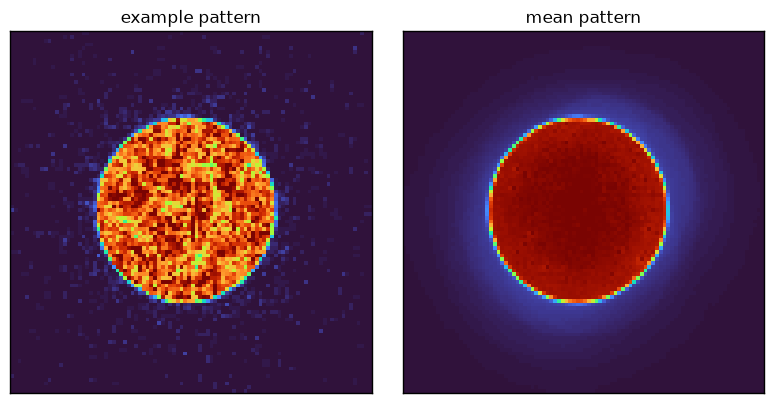

In [4]:
def bin_detector(dataset, factor):
    array = np.asarray(dataset.array, dtype=np.float32)
    ny, nx = array.shape[-2:]
    array = array[..., : ny - ny % factor, : nx - nx % factor]
    array = array.reshape(*array.shape[:2], ny // factor, factor, nx // factor, factor).sum((-3, -1))
    sampling = list(dataset.sampling[:2]) + [s * factor for s in dataset.sampling[-2:]]
    return em.core.datastructures.Dataset4dstem.from_array(
        array, sampling=sampling, units=list(dataset.units)
    )


gold = bin_detector(dataset, 2)
del dataset

em.visualization.show_2d(
    [gold[77, 77].array, gold.mean((0, 1))],
    title=["example pattern", "mean pattern"],
    power=0.5,
    cmap="turbo",
);

In [5]:
energy = 300e3
semiangle_cutoff = 21.9

## Aberrations and rotation

We start from a defocus guess of `C10` = -300 A. Without a rotation angle, the constructor
estimates one from the curl of the centre of mass, which fixes it only modulo 180 degrees.
With the sign of the defocus known, the residual of the reconstruction, `residual_loss()`,
tells the two apart.

In [6]:
direct_ptycho = em.diffractive_imaging.DirectPtychography.from_dataset4d(
    gold,
    energy=energy,
    semiangle_cutoff=semiangle_cutoff,
    aberration_coefs={"C10": -300},
    verbose=False,
    # device='gpu',
)

curl_rotation = direct_ptycho.hyperparameter_state.initial_rotation_angle
residuals = {}
for rotation in (curl_rotation, curl_rotation - 180):
    direct_ptycho.reconstruct(
        deconvolution_kernel="obf", override_rotation_angle=rotation, verbose=False
    )
    residuals[rotation] = direct_ptycho.residual_loss()

print({f"{rotation:g} deg": round(residual, 4) for rotation, residual in residuals.items()})
rotation = min(residuals, key=residuals.get)

{'11 deg': 0.9947, '-169 deg': 0.9687}


`fit_hyperparameters_gradient` then minimizes the residual with respect to the defocus,
the two-fold astigmatism and the rotation together. It starts from the current
`HyperparameterState`, so we store the chosen rotation there first.

In [7]:
direct_ptycho.hyperparameter_state.optimized_rotation_angle = rotation

direct_ptycho.fit_hyperparameters_gradient(
    ("C10", "C12", "phi12", "rotation_angle"),
    deconvolution_kernel="obf",
    verbose=True,
);

Optimized state:

 HyperparameterState(
  initial_aberrations={'C10': -300.0},
  initial_rotation_angle_deg=11.0,
  optimized_aberrations={'C10': -349.1728515625, 'C12': 68.23682403564453, 'phi12': 0.17701365053653717},
  optimized_rotation_angle_deg=-167.82830810546875,
)


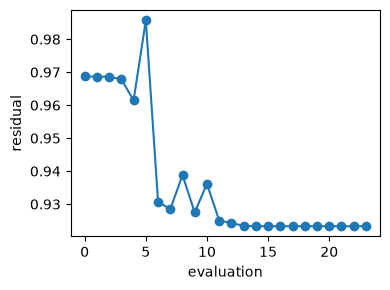

In [8]:
losses = [step["loss"] for step in direct_ptycho._gradient_fit_history]

fig, ax = plt.subplots(figsize=(4, 3))
ax.plot(losses, "o-")
ax.set_xlabel("evaluation")
ax.set_ylabel("residual")
fig.tight_layout()

The residual is the fraction of the data the reconstruction's forward model leaves
unexplained. For a pure-phase object it stays above 0.9 on these data, and
`ptycho_direct_07_complex` shows how much of that is absorption rather than noise. What matters
for fitting is how it changes with the hyperparameters.

Every direct method also has a twin solution, with the detector turned by 180 degrees,
$\chi(\mathbf{k})$ replaced by $-\chi(-\mathbf{k})$ and the object's phase negated, which
explains the data exactly as well. Starting from the known sign of the defocus keeps the fit
away from it.

## Six kernels

`_reconstruct_all_permutations` runs every kernel with the same settings, here upsampled twice.
The scan step is about six times coarser than the bright field's band limit needs, so
upsampling recovers resolution beyond the scan's own Nyquist frequency.

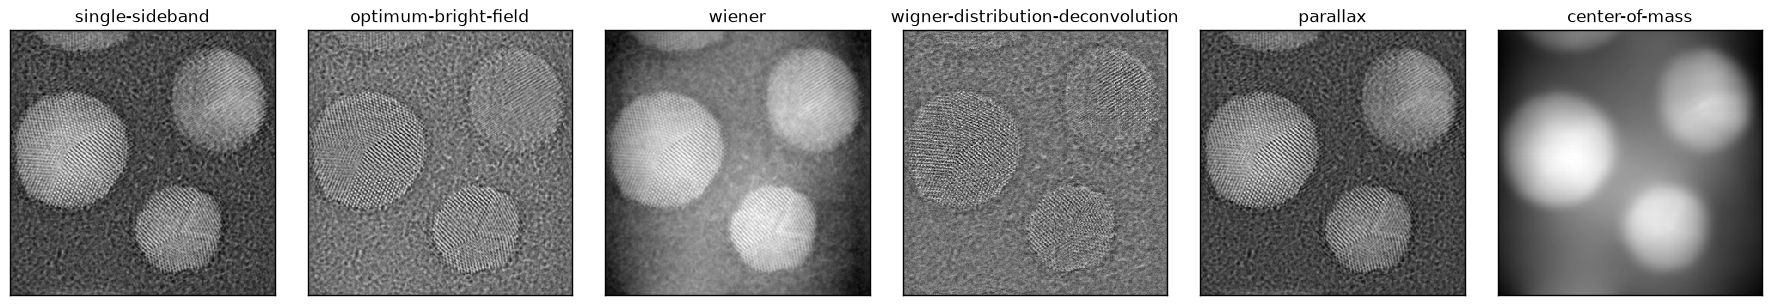

In [9]:
recons = direct_ptycho._reconstruct_all_permutations(upsampling_factor=2)

em.visualization.show_2d(
    recons,
    title=["single-sideband", "optimum-bright-field", "wiener",
           "wigner-distribution-deconvolution", "parallax", "center-of-mass"],
    norm="minmax",
    axsize=(3, 3),
);

SSB, OBF and parallax give similar images. The Wiener estimate keeps the lowest spatial
frequencies at full strength where OBF fades them, and on these data it shows a slow variation
across the field that the weak-object model does not explain. The WDD image is noisier at
this dose. The iCoM image is limited by the 350 A defocus, which spreads the probe.

## Tilt-corrected dark field

`TiltCorrectedDarkField` uses the dark-field pixels the bright-field classes discard. It
shifts angular segments of the dark-field annulus by the aberration gradient two thirds of the
way to the aperture edge (Ma et al.) and averages them. `from_direct_ptychography` copies the
fitted hyperparameters, and `fuse_full_field` takes each spatial frequency from the bright
field where its transfer is strong and from the dark field where it is weak.

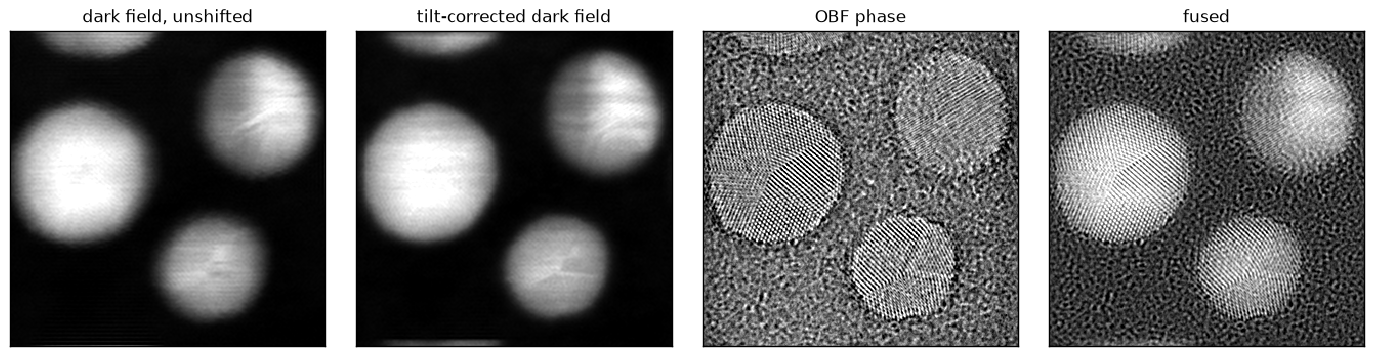

In [10]:
tcdf = em.diffractive_imaging.TiltCorrectedDarkField.from_direct_ptychography(direct_ptycho, gold)

unshifted = tcdf.reconstruct(
    override_aberration_coefs={"C10": 0, "C12": 0}, upsampling_factor=2, verbose=False
).corrected_bf.cpu().numpy()
dark_field = tcdf.reconstruct(upsampling_factor=2, verbose=False).corrected_bf.cpu().numpy()

direct_ptycho.reconstruct(deconvolution_kernel="obf", upsampling_factor=2, verbose=False)
bright_field = direct_ptycho.corrected_bf.cpu().numpy()
fused = em.diffractive_imaging.fuse_full_field(
    bright_field,
    dark_field,
    em.diffractive_imaging.bright_field_transfer(direct_ptycho, upsampling_factor=2),
)

em.visualization.show_2d(
    [unshifted, dark_field, bright_field, fused],
    title=["dark field, unshifted", "tilt-corrected dark field", "OBF phase", "fused"],
    axsize=(3.5, 3.5),
);

Without the shifts the segments blur each other, since at 350 A of defocus each sees the
specimen displaced by the aberration gradient at its own scattering angle. The corrected
dark field is sharper at the particles' edges. As Ma et al. note, the dark-field
intensity is not linear in the potential, so the relative weight of the two in the fused image
is a choice rather than a calibration.

## Summary

| option | call |
|---|---|
| gradient fit | `fit_hyperparameters_gradient(("C10", "C12", "phi12", "rotation_angle"))` |
| all kernels | `_reconstruct_all_permutations(upsampling_factor=2)` |
| tilt-corrected dark field | `TiltCorrectedDarkField.from_direct_ptychography(direct_ptycho, gold)` |
| fusion | `fuse_full_field(bright_field, dark_field, bright_field_transfer(direct_ptycho))` |